# Walmart Retail Sales Prediction

## Project Overview

This project focuses on analyzing Walmart's historical retail sales data and predicting future weekly sales using Machine Learning.

## Objectives
- Analyze historical retail sales patterns.
- Explore factors affecting weekly sales.
- Build and compare Machine Learning models.
- Predict weekly sales using the best-performing model.

## Technologies Used
Python, Pandas, NumPy, Matplotlib, and Scikit-learn.


In [2]:
print("Walmart Retail Sales Prediction Project")
print("Notebook is ready!")

Walmart Retail Sales Prediction Project
Notebook is ready!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving stores.csv to stores.csv
Saving features .csv to features .csv
Saving sampleSubmission.csv to sampleSubmission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


In [53]:
import os

if os.path.exists('/content/features .csv'):
    os.rename('/content/features .csv', '/content/features.csv')
    print("Features file renamed successfully!")

elif os.path.exists('/content/features.csv'):
    print("Features file is already correctly named.")

else:
    print("Features file not found. Please check the uploaded files.")

Features file is already correctly named.


In [5]:
import os

os.rename('/content/features .csv', '/content/features.csv')

print("Renamed successfully!")
print(os.listdir('/content'))

Renamed successfully!
['.config', 'sampleSubmission.csv', 'test.csv', 'train.csv', 'features.csv', 'stores.csv', 'sample_data']


In [55]:
import pandas as pd

# Load the Walmart datasets
train_df = pd.read_csv('/content/train.csv')
test_df = pd.read_csv('/content/test.csv')
features_df = pd.read_csv('/content/features.csv')
stores_df = pd.read_csv('/content/stores.csv')

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [7]:
print("TRAIN DATA:", train_df.shape)
print("TEST DATA:", test_df.shape)
print("FEATURES DATA:", features_df.shape)
print("STORES DATA:", stores_df.shape)
print("SUBMISSION DATA:", submission_df.shape)

TRAIN DATA: (421570, 5)
TEST DATA: (115064, 4)
FEATURES DATA: (8190, 12)
STORES DATA: (45, 3)
SUBMISSION DATA: (115064, 2)


In [8]:
print("First 5 rows of Training Data:")
display(train_df.head())

First 5 rows of Training Data:


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [9]:
print("FEATURES DATA")
display(features_df.head())

print("STORES DATA")
display(stores_df.head())

print("TEST DATA")
display(test_df.head())

FEATURES DATA


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


STORES DATA


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


TEST DATA


,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False


In [10]:
print("Missing Values in Training Data:")
print(train_df.isnull().sum())

print("\nMissing Values in Features Data:")
print(features_df.isnull().sum())

print("\nMissing Values in Stores Data:")
print(stores_df.isnull().sum())

print("\nMissing Values in Test Data:")
print(test_df.isnull().sum())

Missing Values in Training Data:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

Missing Values in Features Data:
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64

Missing Values in Stores Data:
Store    0
Type     0
Size     0
dtype: int64

Missing Values in Test Data:
Store        0
Dept         0
Date         0
IsHoliday    0
dtype: int64


In [11]:
print("Duplicate rows in Training Data:", train_df.duplicated().sum())

print("Duplicate rows in Test Data:", test_df.duplicated().sum())

print("Duplicate rows in Features Data:", features_df.duplicated().sum())

print("Duplicate rows in Stores Data:", stores_df.duplicated().sum())

Duplicate rows in Training Data: 0
Duplicate rows in Test Data: 0
Duplicate rows in Features Data: 0
Duplicate rows in Stores Data: 0


In [12]:
print("TRAIN DATA TYPES")
print(train_df.dtypes)

print("\nFEATURES DATA TYPES")
print(features_df.dtypes)

print("\nSTORES DATA TYPES")
print(stores_df.dtypes)

print("\nTEST DATA TYPES")
print(test_df.dtypes)

TRAIN DATA TYPES
Store             int64
Dept              int64
Date             object
Weekly_Sales    float64
IsHoliday          bool
dtype: object

FEATURES DATA TYPES
Store             int64
Date             object
Temperature     float64
Fuel_Price      float64
MarkDown1       float64
MarkDown2       float64
MarkDown3       float64
MarkDown4       float64
MarkDown5       float64
CPI             float64
Unemployment    float64
IsHoliday          bool
dtype: object

STORES DATA TYPES
Store     int64
Type     object
Size      int64
dtype: object

TEST DATA TYPES
Store         int64
Dept          int64
Date         object
IsHoliday      bool
dtype: object


In [13]:
# Convert Date columns into datetime format

train_df['Date'] = pd.to_datetime(train_df['Date'])
test_df['Date'] = pd.to_datetime(test_df['Date'])
features_df['Date'] = pd.to_datetime(features_df['Date'])

print("Date columns converted successfully!")

print("\nTraining Date Type:", train_df['Date'].dtype)
print("Testing Date Type:", test_df['Date'].dtype)
print("Features Date Type:", features_df['Date'].dtype)

Date columns converted successfully!

Training Date Type: datetime64[ns]
Testing Date Type: datetime64[ns]
Features Date Type: datetime64[ns]


In [14]:
print("WEEKLY SALES SUMMARY")

print("Total Sales:", train_df['Weekly_Sales'].sum())
print("Average Sales:", train_df['Weekly_Sales'].mean())
print("Median Sales:", train_df['Weekly_Sales'].median())
print("Maximum Sales:", train_df['Weekly_Sales'].max())
print("Minimum Sales:", train_df['Weekly_Sales'].min())

WEEKLY SALES SUMMARY
Total Sales: 6737218987.110001
Average Sales: 15981.258123467042
Median Sales: 7612.03
Maximum Sales: 693099.36
Minimum Sales: -4988.94


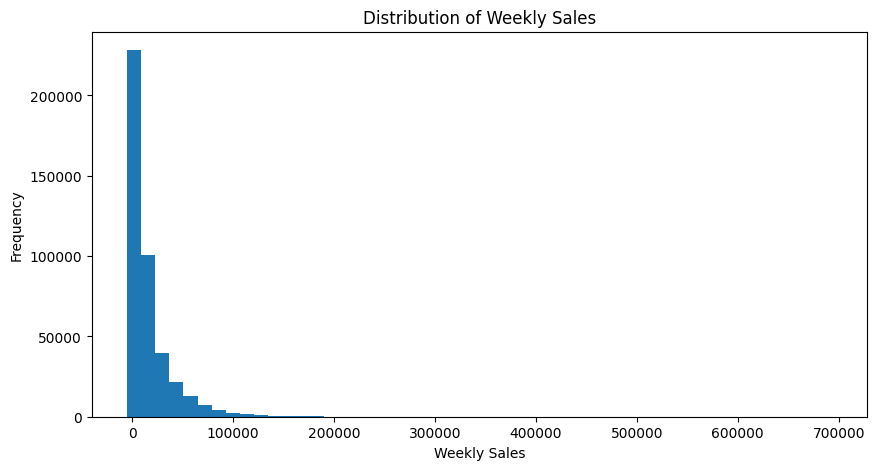

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(train_df['Weekly_Sales'], bins=50)

plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')

plt.show()

In [16]:
# Calculate total sales for each store

store_sales = train_df.groupby('Store')['Weekly_Sales'].sum()

# Display the top 10 stores
top_10_stores = store_sales.sort_values(ascending=False).head(10)

print("Top 10 Stores by Total Sales:")
display(top_10_stores)

Top 10 Stores by Total Sales:


,Weekly_Sales
Store,
20,3.013978e+08
4,2.995440e+08
14,2.889999e+08
13,2.865177e+08
2,2.753824e+08
10,2.716177e+08
27,2.538559e+08
6,2.237561e+08
1,2.224028e+08


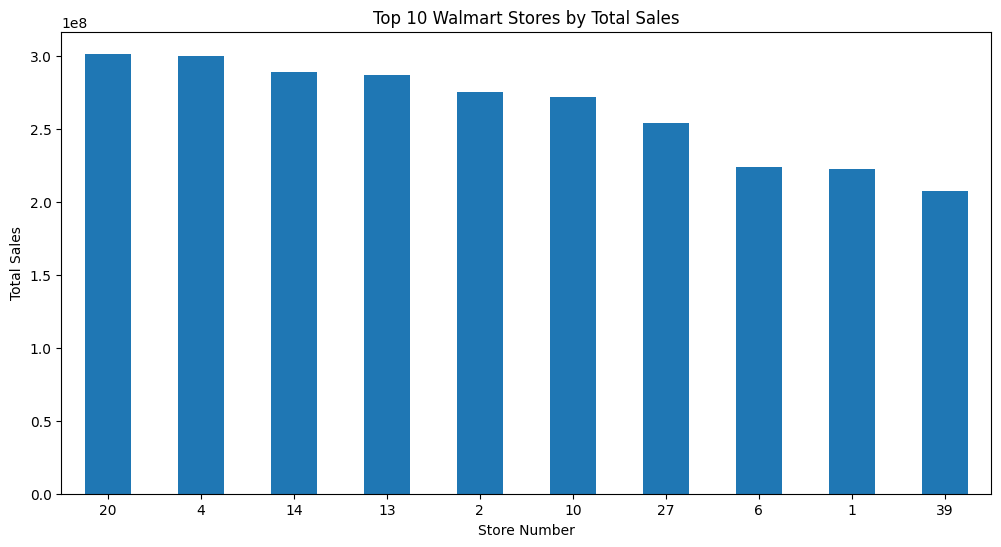

In [17]:
plt.figure(figsize=(12, 6))

top_10_stores.plot(kind='bar')

plt.title('Top 10 Walmart Stores by Total Sales')
plt.xlabel('Store Number')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

In [18]:
# Merge training data with store information
sales_with_stores = train_df.merge(
    stores_df,
    on='Store',
    how='left'
)

# Calculate average weekly sales by store type
type_sales = sales_with_stores.groupby('Type')['Weekly_Sales'].mean()

print("Average Weekly Sales by Store Type:")
display(type_sales)

Average Weekly Sales by Store Type:


,Weekly_Sales
Type,
A,20099.568043
B,12237.075977
C,9519.532538


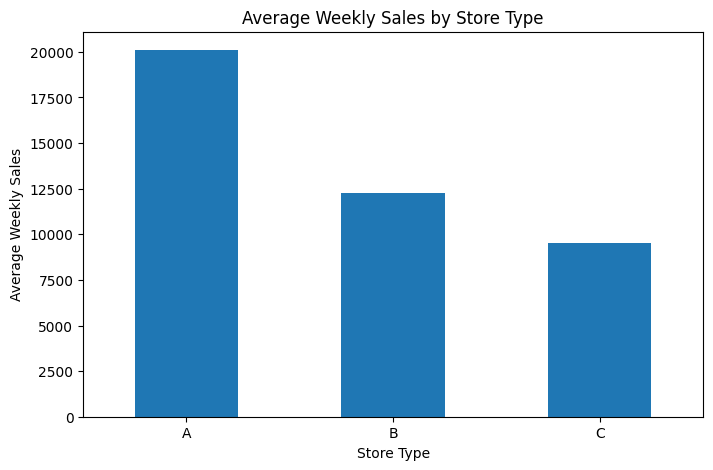

In [19]:
plt.figure(figsize=(8, 5))

type_sales.plot(kind='bar')

plt.title('Average Weekly Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Weekly Sales')
plt.xticks(rotation=0)

plt.show()

In [20]:
# Calculate average weekly sales for each store
average_store_sales = train_df.groupby('Store')['Weekly_Sales'].mean()

# Combine average sales with store information
store_analysis = stores_df.merge(
    average_store_sales,
    on='Store',
    how='left'
)

print("Store Size and Average Weekly Sales:")
display(store_analysis.head(10))

Store Size and Average Weekly Sales:


,Store,Type,Size,Weekly_Sales
0,1,A,151315,21710.543621
1,2,A,202307,26898.070031
2,3,B,37392,6373.033983
3,4,A,205863,29161.210415
4,5,B,34875,5053.415813
5,6,A,202505,21913.243624
6,7,B,70713,8358.766148
7,8,A,155078,13133.014768
8,9,B,125833,8772.890379
9,10,B,126512,26332.303819


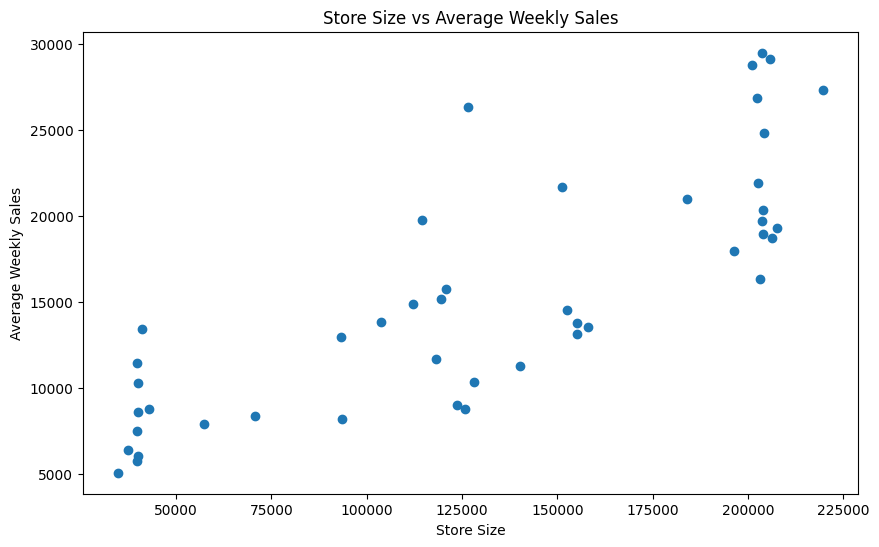

In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    store_analysis['Size'],
    store_analysis['Weekly_Sales']
)

plt.title('Store Size vs Average Weekly Sales')
plt.xlabel('Store Size')
plt.ylabel('Average Weekly Sales')

plt.show()

In [22]:
holiday_sales = train_df.groupby('IsHoliday')['Weekly_Sales'].mean()

print("Average Weekly Sales:")
print(holiday_sales)

Average Weekly Sales:
IsHoliday
False    15901.445069
True     17035.823187
Name: Weekly_Sales, dtype: float64


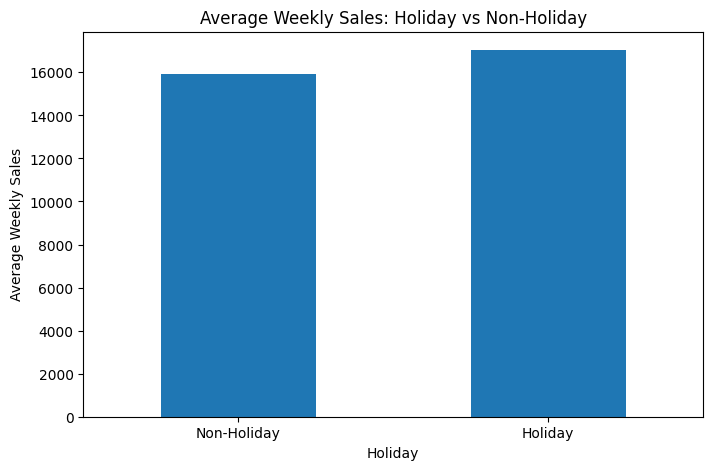

In [23]:
holiday_sales.plot(
    kind='bar',
    figsize=(8, 5),
    title='Average Weekly Sales: Holiday vs Non-Holiday'
)

plt.xlabel('Holiday')
plt.ylabel('Average Weekly Sales')
plt.xticks([0, 1], ['Non-Holiday', 'Holiday'], rotation=0)
plt.show()

In [24]:
train_df['Month'] = train_df['Date'].dt.month

monthly_sales = train_df.groupby('Month')['Weekly_Sales'].mean()

print("Average Weekly Sales by Month:")
display(monthly_sales)

Average Weekly Sales by Month:


,Weekly_Sales
Month,
1,14126.075111
2,16008.779217
3,15416.657597
4,15650.338357
5,15776.337202
6,16326.137002
7,15861.419650
8,16062.516933
9,15095.886154


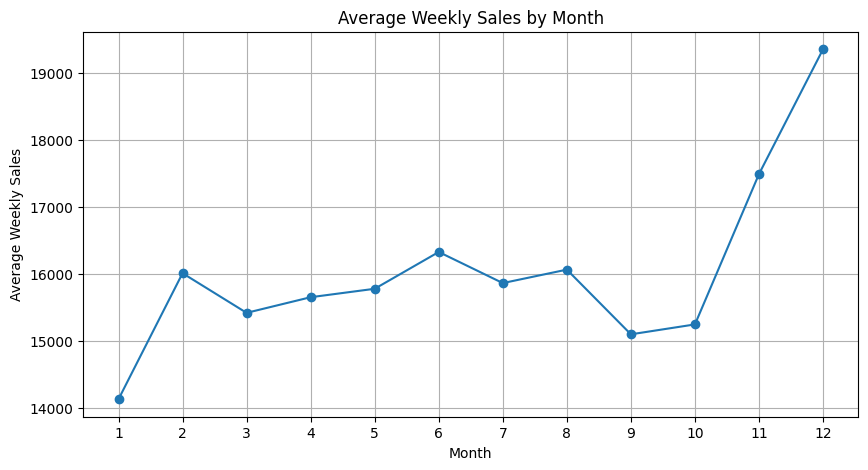

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Average Weekly Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Weekly Sales')
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [26]:
train_df['Year'] = train_df['Date'].dt.year

yearly_sales = train_df.groupby('Year')['Weekly_Sales'].mean()

print("Average Weekly Sales by Year:")
display(yearly_sales)

Average Weekly Sales by Year:


,Weekly_Sales
Year,
2010,16270.275737
2011,15954.070675
2012,15694.948597


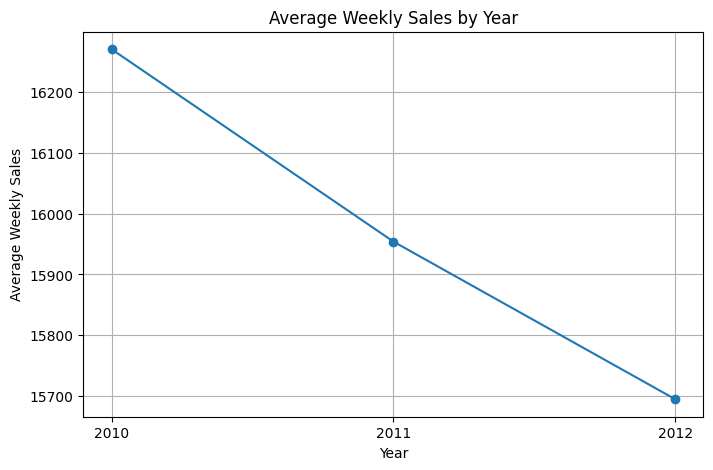

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(yearly_sales.index, yearly_sales.values, marker='o')

plt.title('Average Weekly Sales by Year')
plt.xlabel('Year')
plt.ylabel('Average Weekly Sales')
plt.xticks(yearly_sales.index)
plt.grid(True)

plt.show()

In [28]:
# Merge sales data with store information
sales_data = train_df.merge(
    stores_df,
    on='Store',
    how='left'
)

# Merge with additional features
sales_data = sales_data.merge(
    features_df,
    on=['Store', 'Date', 'IsHoliday'],
    how='left'
)

# Display the combined dataset
print("Combined Dataset Shape:", sales_data.shape)

display(sales_data.head())

Combined Dataset Shape: (421570, 18)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Month,Year,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,2,2010,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,1,1,2010-02-12,46039.49,True,2,2010,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106
2,1,1,2010-02-19,41595.55,False,2,2010,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106
3,1,1,2010-02-26,19403.54,False,2,2010,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106
4,1,1,2010-03-05,21827.90,False,3,2010,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106


In [29]:
# Check missing values in the combined dataset
missing_values = sales_data.isnull().sum()

# Display columns with missing values
missing_values = missing_values[missing_values > 0]

print("Missing Values:")
display(missing_values)

Missing Values:


,0
MarkDown1,270889
MarkDown2,310322
MarkDown3,284479
MarkDown4,286603
MarkDown5,270138


In [30]:
# Fill missing Markdown values with 0
markdown_columns = [
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5'
]

sales_data[markdown_columns] = sales_data[markdown_columns].fillna(0)

# Verify missing values
print("Total Missing Values:", sales_data.isnull().sum().sum())

Total Missing Values: 0


In [31]:
# Check duplicate records
duplicate_count = sales_data.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 0


In [32]:
# Convert Store Type into numerical columns
sales_data = pd.get_dummies(
    sales_data,
    columns=['Type'],
    drop_first=True,
    dtype=int
)

# Display the updated dataset
print("Updated Dataset Shape:", sales_data.shape)

display(sales_data.head())

Updated Dataset Shape: (421570, 19)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Month,Year,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type_B,Type_C
0,1,1,2010-02-05,24924.50,False,2,2010,151315,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,0,0
1,1,1,2010-02-12,46039.49,True,2,2010,151315,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,0,0
2,1,1,2010-02-19,41595.55,False,2,2010,151315,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,0,0
3,1,1,2010-02-26,19403.54,False,2,2010,151315,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,0,0
4,1,1,2010-03-05,21827.90,False,3,2010,151315,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,0,0


In [33]:
# Separate input features and target variable
X = sales_data.drop(columns=['Weekly_Sales', 'Date'])
y = sales_data['Weekly_Sales']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (421570, 17)
Target Variable Shape: (421570,)


In [34]:
# Check the date range in the dataset
print("Start Date:", sales_data['Date'].min())
print("End Date:", sales_data['Date'].max())

Start Date: 2010-02-05 00:00:00
End Date: 2012-10-26 00:00:00


In [35]:
# Sort the data by date
sales_data = sales_data.sort_values('Date').reset_index(drop=True)

# Use the 80th percentile date as the split boundary
split_date = sales_data['Date'].quantile(0.80)

# Split into training and validation sets
train_data = sales_data[sales_data['Date'] < split_date]
valid_data = sales_data[sales_data['Date'] >= split_date]

# Separate features and target
X_train = train_data.drop(columns=['Weekly_Sales', 'Date'])
y_train = train_data['Weekly_Sales']

X_valid = valid_data.drop(columns=['Weekly_Sales', 'Date'])
y_valid = valid_data['Weekly_Sales']

print("Split Date:", split_date)
print("Training Features:", X_train.shape)
print("Validation Features:", X_valid.shape)

Split Date: 2012-04-13 00:00:00
Training Features: (335761, 17)
Validation Features: (85809, 17)


In [36]:
from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions
linear_predictions = linear_model.predict(X_valid)

# Calculate evaluation metrics
linear_mae = mean_absolute_error(y_valid, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_valid, linear_predictions))
linear_r2 = r2_score(y_valid, linear_predictions)

print("Linear Regression Performance")
print("--------------------------------")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R2 Score:", round(linear_r2, 4))

Linear Regression Performance
--------------------------------
MAE: 14541.72
RMSE: 20892.09
R2 Score: 0.0947


In [38]:
from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [39]:
rf_predictions = rf_model.predict(X_valid)

rf_mae = mean_absolute_error(y_valid, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_predictions))
rf_r2 = r2_score(y_valid, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 4))

Random Forest Results
---------------------
MAE: 2280.96
RMSE: 4515.34
R² Score: 0.9577


In [40]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [linear_mae, rf_mae],
    'RMSE': [linear_rmse, rf_rmse],
    'R2 Score': [linear_r2, rf_r2]
})

display(model_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,14541.7226,20892.0937,0.0947
1,Random Forest,2280.9603,4515.3380,0.9577


In [41]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.head(10))

,Feature,Importance
1,Dept,0.637027
5,Size,0.197416
0,Store,0.051292
3,Month,0.028728
13,CPI,0.025650
10,MarkDown3,0.013557
15,Type_B,0.011410
14,Unemployment,0.011200
6,Temperature,0.008401
2,IsHoliday,0.005288


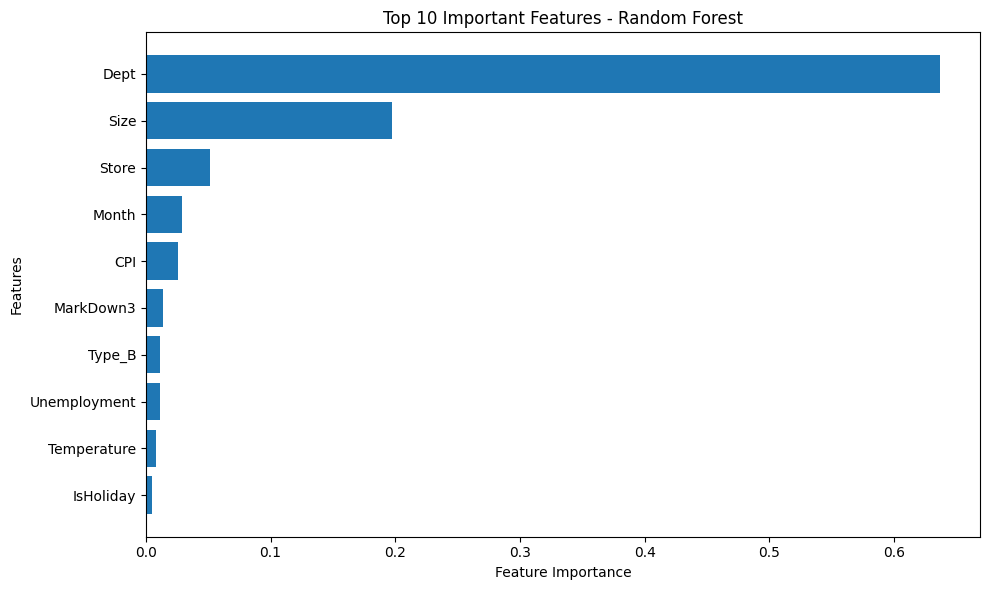

In [43]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(10).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [44]:
train_predictions = rf_model.predict(X_train)

train_r2 = r2_score(y_train, train_predictions)
valid_r2 = r2_score(y_valid, rf_predictions)

print("Training R² Score:", round(train_r2, 4))
print("Validation R² Score:", round(valid_r2, 4))

Training R² Score: 0.9683
Validation R² Score: 0.9577


In [45]:
test_data = test_df.merge(
    stores_df,
    on='Store',
    how='left'
)

test_data = test_data.merge(
    features_df,
    on=['Store', 'Date', 'IsHoliday'],
    how='left'
)

print("Test Dataset Shape:", test_data.shape)
display(test_data.head())

Test Dataset Shape: (115064, 15)


,Store,Dept,Date,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2012-11-02,False,A,151315,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573
1,1,1,2012-11-09,False,A,151315,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573
2,1,1,2012-11-16,False,A,151315,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573
3,1,1,2012-11-23,True,A,151315,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573
4,1,1,2012-11-30,False,A,151315,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573


In [46]:
# Fill missing Markdown values
markdown_columns = [
    'MarkDown1', 'MarkDown2', 'MarkDown3',
    'MarkDown4', 'MarkDown5'
]

test_data[markdown_columns] = test_data[markdown_columns].fillna(0)

# Create Month and Year features
test_data['Month'] = test_data['Date'].dt.month
test_data['Year'] = test_data['Date'].dt.year

print("Missing values after cleaning:")
print(test_data[markdown_columns].isnull().sum())

print("\nTest Dataset Shape:", test_data.shape)

Missing values after cleaning:
MarkDown1    0
MarkDown2    0
MarkDown3    0
MarkDown4    0
MarkDown5    0
dtype: int64

Test Dataset Shape: (115064, 17)


In [47]:
test_data = pd.get_dummies(
    test_data,
    columns=['Type'],
    drop_first=True,
    dtype=int
)

print("Test Dataset Shape:", test_data.shape)
display(test_data.head())

Test Dataset Shape: (115064, 18)


,Store,Dept,Date,IsHoliday,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Month,Year,Type_B,Type_C
0,1,1,2012-11-02,False,151315,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,11,2012,0,0
1,1,1,2012-11-09,False,151315,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,11,2012,0,0
2,1,1,2012-11-16,False,151315,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,11,2012,0,0
3,1,1,2012-11-23,True,151315,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,11,2012,0,0
4,1,1,2012-11-30,False,151315,52.34,3.207,2460.03,0.00,3838.35,150.57,6966.34,223.610984,6.573,11,2012,0,0


In [48]:
X_test = test_data.drop(columns=['Date'])

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Training Features Shape:", X_train.shape)
print("Test Features Shape:", X_test.shape)

print("\nDo columns match?",
      list(X_train.columns) == list(X_test.columns))

Training Features Shape: (335761, 17)
Test Features Shape: (115064, 17)

Do columns match? True


In [49]:
rf_test_predictions = rf_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(rf_test_predictions))

print("\nFirst 10 predictions:")
print(rf_test_predictions[:10])

Predictions generated successfully!
Number of predictions: 115064

First 10 predictions:
[19722.67504823 18811.36791537 19128.7628898  19814.06537884
 20207.52238669 40244.96049409 37848.97050642 47188.87372855
 20894.56141311 18155.77881568]


In [50]:
submission = pd.DataFrame({
    'Id': (
        test_df['Store'].astype(str) + '_' +
        test_df['Dept'].astype(str) + '_' +
        test_df['Date'].dt.strftime('%Y-%m-%d')
    ),
    'Weekly_Sales': rf_test_predictions
})

print("Submission Shape:", submission.shape)
display(submission.head())

Submission Shape: (115064, 2)


,Id,Weekly_Sales
0,1_1_2012-11-02,19722.675048
1,1_1_2012-11-09,18811.367915
2,1_1_2012-11-16,19128.762890
3,1_1_2012-11-23,19814.065379
4,1_1_2012-11-30,20207.522387


In [51]:
submission.to_csv('walmart_sales_predictions.csv', index=False)

print("Prediction file saved successfully!")

Prediction file saved successfully!


In [52]:
import os

file_path = '/content/walmart_sales_predictions.csv'

print("File exists:", os.path.exists(file_path))
print("File size:", round(os.path.getsize(file_path) / (1024 * 1024), 2), "MB")

File exists: True
File size: 3.84 MB


##  Conclusion

In this project, Walmart's historical retail sales data was analyzed to identify sales patterns and understand important factors influencing weekly sales.

Two Machine Learning models were developed and evaluated: Linear Regression and Random Forest.

The Random Forest model performed better on the validation dataset, achieving:

- **MAE:** 2,280.96
- **RMSE:** 4,515.34
- **R² Score:** 0.9577

Feature importance analysis showed that Department, Store Size, and Store were among the most influential features used by the model.

Finally, the trained Random Forest model was used to generate weekly sales predictions for the test dataset.
